# Pixel art experiments: mouse photo â†’ monochrome LED grid

Goal: a black/white 8Ã—8 (also 16Ã—16, 32Ã—32) grid that still reads as the subject.
Test image: a grey mouse on a busy patterned bedsheet, the worst case for a naive threshold.

../uploads\bf108c3c482c4dc3ad8c4872435b1eb3.jpg (768, 1024)


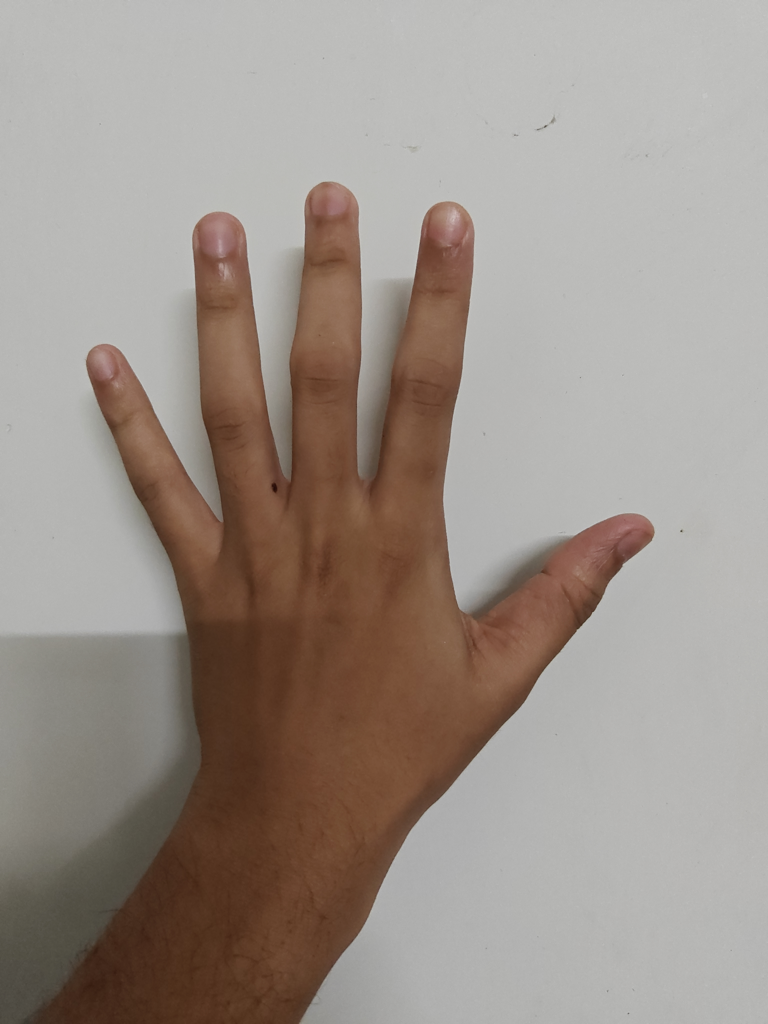

In [1]:
import numpy as np, glob, time
from PIL import Image, ImageOps, ImageFilter
import matplotlib.pyplot as plt

SRC = sorted(glob.glob('../uploads/*'))[-1]
img = ImageOps.exif_transpose(Image.open(SRC)).convert('RGB')
img.thumbnail((1024, 1024))      # plenty for an 8..32 px target, keeps models fast
print(SRC, img.size)
SIZES = (8, 16, 32)

def show(grids, title):
    fig, ax = plt.subplots(1, len(grids), figsize=(3*len(grids), 3))
    for a, (n, g) in zip(np.atleast_1d(ax), grids.items()):
        a.imshow(g, cmap='gray', vmin=0, vmax=1, interpolation='nearest'); a.set_title(f'{title} {n}Ã—{n}'); a.axis('off')
    plt.show()

def square(im):  # center crop to square
    return ImageOps.fit(im, (min(im.size),)*2)
img

## 1. Baseline: what the app does now (mean threshold)

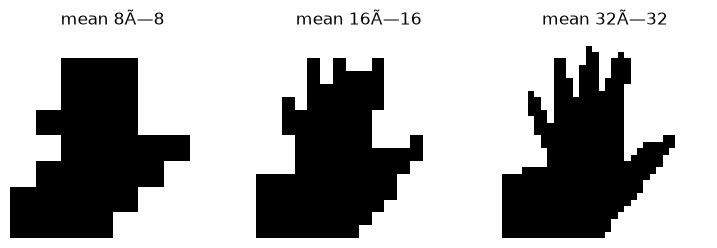

In [2]:
def mean_thresh(im, n):
    g = ImageOps.autocontrast(square(im).convert('L').resize((n, n), Image.LANCZOS))
    a = np.asarray(g, dtype=float)
    return a > a.mean()
show({n: mean_thresh(img, n) for n in SIZES}, 'mean')

## 2. Otsu threshold + Floydâ€“Steinberg dither
Dither spreads error so tones look right, but at 8Ã—8 there is no room for tones; the pattern still wins.

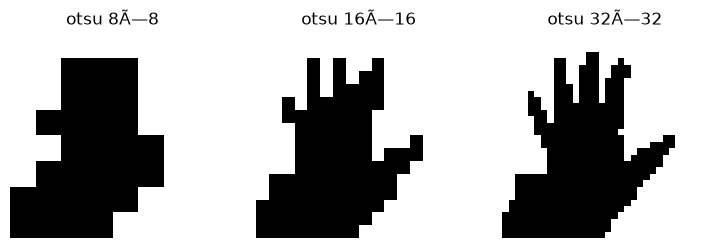

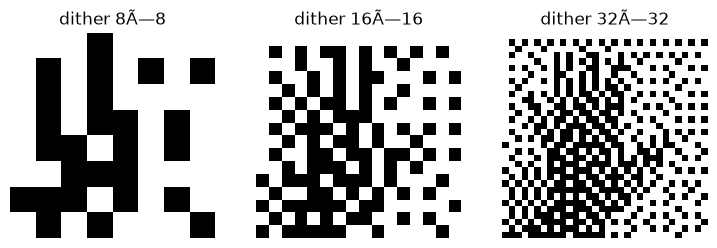

In [3]:
def otsu(a):
    hist, edges = np.histogram(a, bins=256, range=(0, 255))
    p = hist / hist.sum(); w0 = np.cumsum(p); mu = np.cumsum(p * np.arange(256)); muT = mu[-1]
    with np.errstate(divide='ignore', invalid='ignore'):
        var = (muT*w0 - mu)**2 / (w0*(1-w0))
    return np.nanargmax(var)

def otsu_grid(im, n):
    a = np.asarray(square(im).convert('L').resize((n, n), Image.LANCZOS), dtype=float)
    return a > otsu(a)

def dither(im, n):   # Pillow's convert('1') is Floydâ€“Steinberg
    return np.asarray(square(im).convert('L').resize((n, n), Image.LANCZOS).convert('1'))
show({n: otsu_grid(img, n) for n in SIZES}, 'otsu')
show({n: dither(img, n) for n in SIZES}, 'dither')

## 3. Edges only

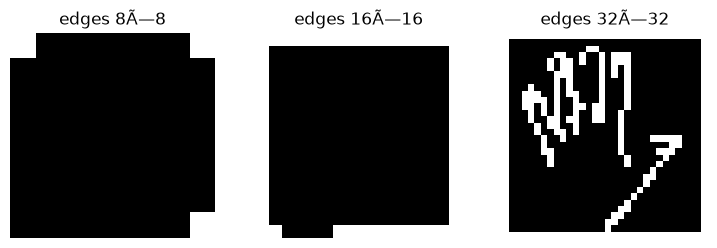

In [4]:
def edges(im, n):
    e = square(im).convert('L').filter(ImageFilter.GaussianBlur(2)).filter(ImageFilter.FIND_EDGES)
    a = np.asarray(e.resize((n, n), Image.BOX), dtype=float)
    return a > np.percentile(a, 75)
show({n: edges(img, n) for n in SIZES}, 'edges')

## 4. Subject segmentation (open-source models via `rembg`)
Cut the subject out, use the alpha mask as the silhouette. Models are downloaded once to `~/.u2net`.
- `u2net`: classic salient-object model (~170 MB)
- `isnet-general-use`: newer, usually cleaner edges (~170 MB)

C:\Users\sohamm\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


u2net: 3.4s


isnet-general-use: 4.8s


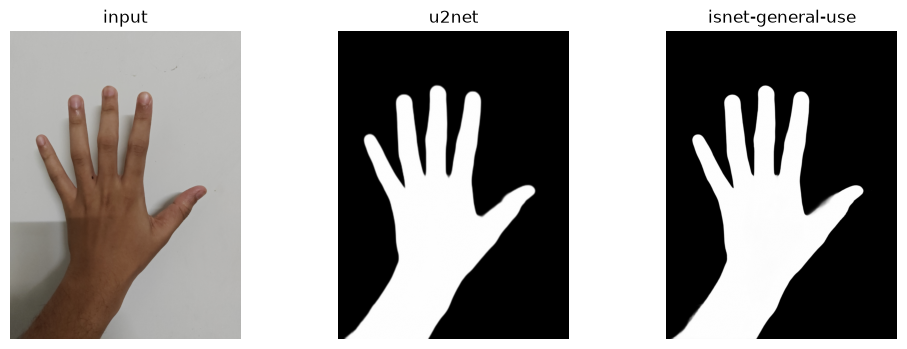

In [5]:
from rembg import remove, new_session
masks = {}
for model in ('u2net', 'isnet-general-use'):
    t = time.time()
    sess = new_session(model)
    out = remove(img, session=sess, only_mask=True)
    masks[model] = out
    print(f'{model}: {time.time()-t:.1f}s')
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(img); ax[0].set_title('input')
for a, (m, mk) in zip(ax[1:], masks.items()): a.imshow(mk, cmap='gray'); a.set_title(m)
[a.axis('off') for a in ax]; plt.show()

### 4a. Silhouette â†’ grid
Crop to the subject's bounding box (with margin) so the mouse fills the matrix, then a cell is ON if â‰¥ 50 % of it is covered by the mask.

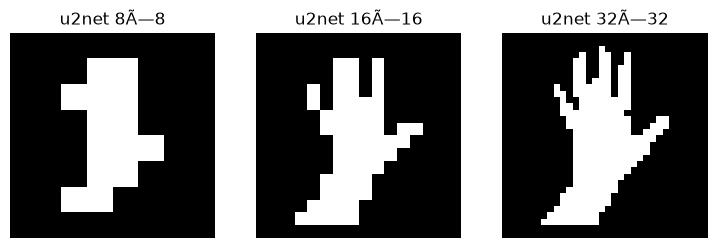

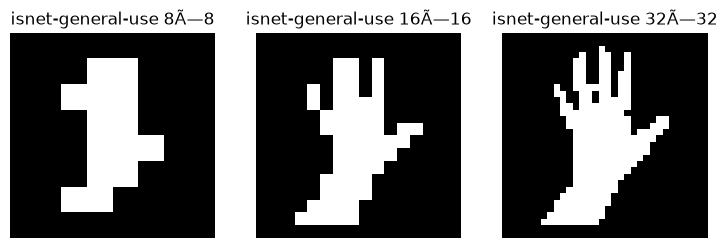

In [6]:
def silhouette(mask, n, margin=0.08, fill=0.5):
    m = np.asarray(mask) > 127
    ys, xs = np.where(m)
    if len(xs) == 0: return np.zeros((n, n), bool)
    x0, x1, y0, y1 = xs.min(), xs.max(), ys.min(), ys.max()
    side = int(max(x1-x0, y1-y0) * (1 + 2*margin))
    cx, cy = (x0+x1)//2, (y0+y1)//2
    box = (cx-side//2, cy-side//2, cx-side//2+side, cy-side//2+side)
    crop = Image.fromarray(m.astype(np.uint8)*255).crop(box)   # pads with black outside
    cov = np.asarray(crop.resize((n, n), Image.BOX), dtype=float) / 255
    return cov >= fill

for model, mk in masks.items():
    show({n: silhouette(mk, n) for n in SIZES}, model)

### 4b. Silhouette + inner detail
Silhouette alone is a blob at 8Ã—8. At 16+ we can carve dark features (scroll wheel, seam) back out: inside the mask, cells darker than the subject's median go OFF.

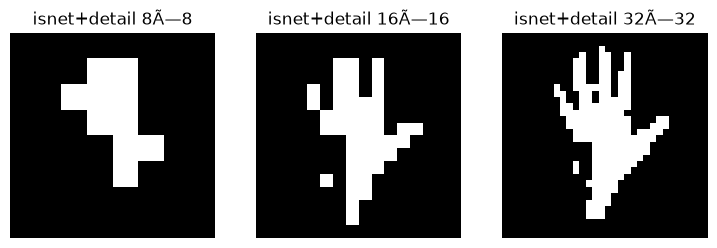

In [7]:
def silhouette_detail(im, mask, n, margin=0.08, fill=0.5, k=0.75):
    m = np.asarray(mask) > 127
    ys, xs = np.where(m)
    x0, x1, y0, y1 = xs.min(), xs.max(), ys.min(), ys.max()
    side = int(max(x1-x0, y1-y0) * (1 + 2*margin)); cx, cy = (x0+x1)//2, (y0+y1)//2
    box = (cx-side//2, cy-side//2, cx-side//2+side, cy-side//2+side)
    cov = np.asarray(Image.fromarray(m.astype(np.uint8)*255).crop(box).resize((n, n), Image.BOX), float)/255
    lum = np.asarray(square(im.crop(box)).convert('L').resize((n, n), Image.BOX), float)
    inside = cov >= fill
    med = np.median(lum[inside]) if inside.any() else 0
    return inside & (lum > med * k)

best = masks['isnet-general-use']
show({n: silhouette_detail(img, best, n) for n in SIZES}, 'isnet+detail')

## 5. Side by side at 8Ã—8 and 16Ã—16

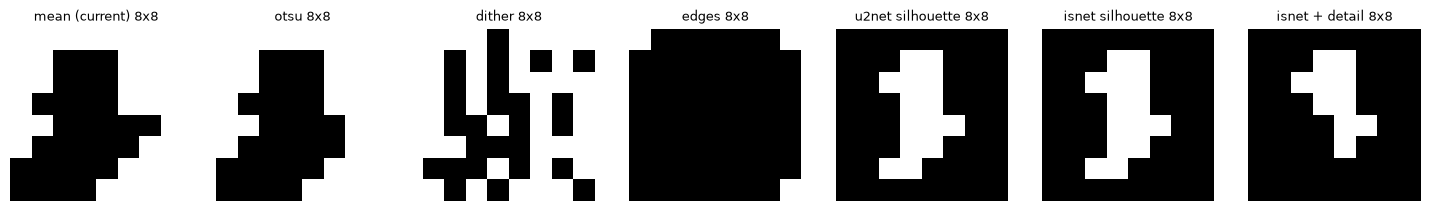

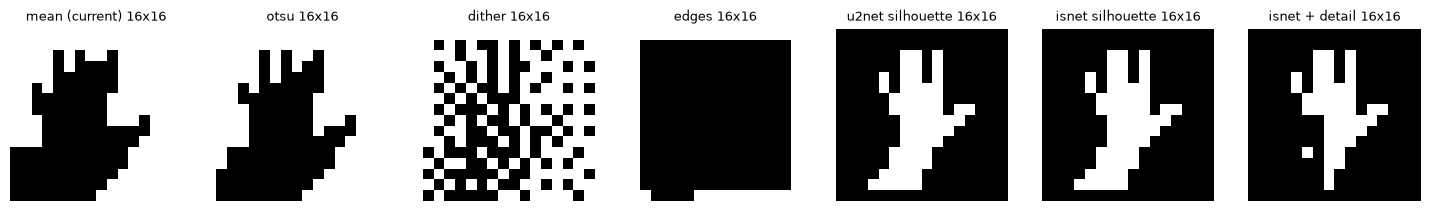

In [8]:
methods = {
    'mean (current)': lambda n: mean_thresh(img, n),
    'otsu': lambda n: otsu_grid(img, n),
    'dither': lambda n: dither(img, n),
    'edges': lambda n: edges(img, n),
    'u2net silhouette': lambda n: silhouette(masks['u2net'], n),
    'isnet silhouette': lambda n: silhouette(masks['isnet-general-use'], n),
    'isnet + detail': lambda n: silhouette_detail(img, masks['isnet-general-use'], n),
}
for n in (8, 16):
    fig, ax = plt.subplots(1, len(methods), figsize=(2.6*len(methods), 2.8))
    for a, (name, f) in zip(ax, methods.items()):
        a.imshow(f(n), cmap='gray', vmin=0, vmax=1, interpolation='nearest'); a.set_title(name + f' {n}x{n}', fontsize=9); a.axis('off')
    plt.show()

## 6. Dump grids as text (what the ESP32 will receive)

In [9]:
for n in (8, 16):
    g = silhouette(masks['isnet-general-use'], n)
    print(f'--- {n}x{n} ---'); print(chr(10).join(''.join('#' if c else '.' for c in r) for r in g))

--- 8x8 ---
........
...##...
..###...
...##...
...###..
...##...
..##....
........
--- 16x16 ---
................
................
......##.#......
......##.#......
....#.##.#......
....#.####......
.....#####......
.....#####.##...
......######....
......#####.....
......####......
.....####.......
.....####.......
....####........
...#####........
................


## 7. 64×64: silhouette + the subject's own edges
At 64 px there is room for inner detail. Three edge detectors, all restricted to the segmented subject:
- **Canny** (classic, no model)
- **Structured Forests** (learned, OpenCV `ximgproc`, 6 MB `models/model.yml.gz`)
- **HED** (deep CNN, Caffe via `cv2.dnn`, 58 MB `models/hed.caffemodel`)

Two styles: *filled* = silhouette with edges carved out, *lines* = outline + edges.

canny 0.00s


structured forests 1.70s


HED 1.43s


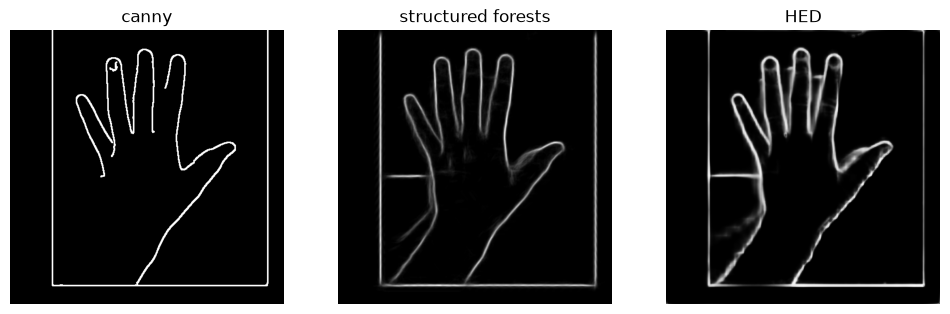

In [10]:
import cv2
M = '../models'
mk = np.asarray(masks['isnet-general-use']) > 127
ys, xs = np.where(mk); x0,x1,y0,y1 = xs.min(),xs.max(),ys.min(),ys.max()
side = int(max(x1-x0,y1-y0)*1.16); cx,cy = (x0+x1)//2,(y0+y1)//2
box = (cx-side//2, cy-side//2, cx-side//2+side, cy-side//2+side)
crop = img.crop(box).resize((512,512)); mcrop = np.asarray(Image.fromarray(mk.astype(np.uint8)*255).crop(box).resize((512,512))) > 127
bgr = cv2.cvtColor(np.asarray(crop), cv2.COLOR_RGB2BGR)
n = 64
def to_grid(a): return np.asarray(Image.fromarray((np.clip(a,0,1)*255).astype(np.uint8)).resize((n,n), Image.BOX), float)/255
inside = to_grid(mcrop.astype(float)) >= 0.5

t=time.time(); canny = cv2.Canny(cv2.GaussianBlur(cv2.cvtColor(bgr,cv2.COLOR_BGR2GRAY),(0,0),2),30,90)/255.0; canny = cv2.dilate(canny,np.ones((3,3),np.uint8)); print(f'canny {time.time()-t:.2f}s')
t=time.time(); sf = cv2.ximgproc.createStructuredEdgeDetection(f'{M}/model.yml.gz').detectEdges(np.float32(bgr)/255); print(f'structured forests {time.time()-t:.2f}s')
class CropLayer:
    def __init__(self, params, blobs): pass
    def getMemoryShapes(self, inputs):
        iS, tS = inputs[0], inputs[1]; self.ys=(iS[2]-tS[2])//2; self.xs=(iS[3]-tS[3])//2; self.ye=self.ys+tS[2]; self.xe=self.xs+tS[3]
        return [[iS[0], iS[1], tS[2], tS[3]]]
    def forward(self, inputs): return [inputs[0][:,:,self.ys:self.ye,self.xs:self.xe]]
try: cv2.dnn_registerLayer('Crop', CropLayer)
except cv2.error: pass
t=time.time(); net = cv2.dnn.readNetFromCaffe(f'{M}/hed.prototxt', f'{M}/hed.caffemodel')
net.setInput(cv2.dnn.blobFromImage(bgr, 1.0, (512,512), (104.00698793,116.66876762,122.67891434), swapRB=False, crop=False)); hed = net.forward()[0,0]; print(f'HED {time.time()-t:.2f}s')

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, (k, v) in zip(ax, {'canny': canny, 'structured forests': sf, 'HED': hed}.items()): a.imshow(v, cmap='gray'); a.set_title(k); a.axis('off')
plt.show()

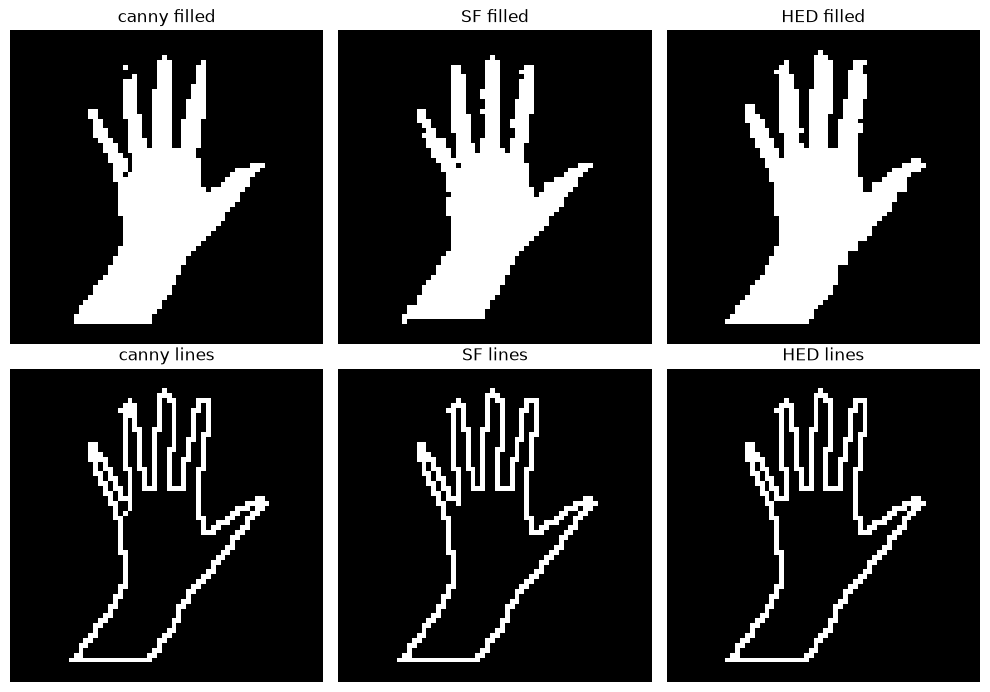

In [11]:
def masked_edges(e, thr):
    e = e.copy(); e[~mcrop] = 0
    return inside & (to_grid(e) > thr)
outline = inside & ~(cv2.erode(inside.astype(np.uint8), np.ones((3,3),np.uint8)) > 0)
res = {}
for name, e, thr in (('canny', canny, 0.15), ('SF', sf, 0.15), ('HED', hed, 0.4)):
    ed = masked_edges(e, thr)
    res[f'{name} filled'] = inside & ~ed
    res[f'{name} lines'] = outline | ed
fig, ax = plt.subplots(2, 3, figsize=(10, 7))
for a, (k, v) in zip(ax.T.flat, res.items()): a.imshow(v, cmap='gray', vmin=0, vmax=1, interpolation='nearest'); a.set_title(k); a.axis('off')
plt.tight_layout(); plt.show()

**Verdict:** Structured Forests gives the cleanest scroll wheel and seam at 64×64, costs 1.5 s on CPU and a 6 MB model, so the app uses it (`pixelate()` in `app.py`). Canny is a free near-equal fallback. HED is noisier at the mask boundary and 10× the download.